# 03 – Models

Tests the hypotheses on the relationship between receiving expansions and the installed base of the base game.

- **H1** – Games with at least one expansion have a larger installed base than comparable games without.
- **H2** – The number of expansions is positively related to the installed base, with diminishing returns.
- **H3** – The relationship is weaker for games in genres whose business model is built around a stream
  of expansions from the start (wargames, miniatures, collectible-component and scenario/campaign games).

**Design.** One observation is one game (snapshot of January 2022). All models are OLS on
`log(1 + owned)` with the same controls, publication-year fixed effects (absorb game age and era,
see notebook 02, Figure 3) and heteroskedasticity-robust (HC1) standard errors. HC1 is used instead of
HC3 because some publication years contain a single game, which makes HC3 undefined.
Group differences enter the model as interactions on all games, not as split samples.

The data are a single snapshot and publishers mainly expand games that already sell, so the
coefficients are associations, not causal effects. A coefficient *b* on a dummy corresponds to
exp(*b*) − 1 more owners.

In [41]:
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import statsmodels.api as sm
import statsmodels.formula.api as smf
from matplotlib.ticker import FuncFormatter
from statsmodels.iolib.summary2 import summary_col
from statsmodels.stats.diagnostic import het_breuschpagan
from statsmodels.stats.outliers_influence import variance_inflation_factor

warnings.filterwarnings("ignore", category=RuntimeWarning)

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
PROCESSED = ROOT / "data" / "processed"
TABLES = ROOT / "output" / "tables"
FIGURES = ROOT / "output" / "figures"

BLUE, ORANGE, GREY = "#2a78d6", "#eb6834", "#52514e"
BIN_LABELS = ["0", "1", "2-3", "4-9", "10+"]
CONTROLS = ["log_playingtime", "minplayers", "maxplayers_capped", "minage", "log_publisher_size", "self_published"]
PCT = FuncFormatter(lambda v, _: f"+{v:.0%}")

plt.style.use("seaborn-v0_8-whitegrid")
plt.rcParams.update({"figure.figsize": (7, 4.5), "savefig.bbox": "tight", "axes.titleweight": "bold",
                     "axes.titlelocation": "left", "legend.frameon": False})

def save_fig(fig, name):
    for ext in ["png"]:
        fig.savefig(FIGURES / f"{name}.{ext}", dpi=300)

def ols(formula, df):
    """OLS with the controls, publication-year fixed effects and HC1 robust standard errors."""
    return smf.ols(f"{formula} + {' + '.join(CONTROLS)} + C(yearpublished)", data=df).fit(cov_type="HC1")

def effect(model, terms):
    """Estimate, robust SE, 95% CI and p-value of one coefficient or a sum of coefficients ("a + b")."""
    test = model.t_test(f"{terms} = 0")
    ci_low, ci_high = np.squeeze(test.conf_int())
    coef = float(np.squeeze(test.effect))
    return {"coef": coef, "se": float(np.squeeze(test.sd)), "ci_low": ci_low, "ci_high": ci_high,
            "p_value": float(np.squeeze(test.pvalue)), "pct_effect": np.exp(coef) - 1}

def pct(b):
    return np.exp(b) - 1

def p_text(p):
    return "p < 0.001" if p < 0.001 else f"p = {p:.3f}"

def regression_table(models, names, terms, labels):
    """Coefficients with stars and robust SEs below; fixed-effect dummies are not shown."""
    table = summary_col(models, model_names=names, stars=True, float_format="%.3f", regressor_order=terms,
                        drop_omitted=True, fixed_effects=["yearpublished"],
                        info_dict={"Observations": lambda m: f"{int(m.nobs):,}"}).tables[0]
    table.index = [labels.get(i, i) for i in table.index]
    return table.rename(index={"yearpublished FE": "Year fixed effects"})

games = pd.read_csv(PROCESSED / "games_clean.csv")
games["expansion_bin"] = pd.Categorical(games["expansion_bin"].astype(str), categories=BIN_LABELS)
data = games.dropna(subset=["log_owned"] + CONTROLS)
print(f"Estimation sample: {len(data):,} of {len(games):,} games ({data['has_expansion'].sum():,} with an expansion)")

LABELS = {
    "has_expansion": "Has expansion",
    "log_n_expansions": "log(1 + number of expansions)",
    "C(expansion_bin)[T.1]": "1 expansion",
    "C(expansion_bin)[T.2-3]": "2-3 expansions",
    "C(expansion_bin)[T.4-9]": "4-9 expansions",
    "C(expansion_bin)[T.10+]": "10+ expansions",
    "planned_expansion_genre": "Planned-expansion genre",
    "has_expansion:planned_expansion_genre": "Has expansion x planned genre",
    "average": "Average rating",
    "log_playingtime": "log(playing time)",
    "minplayers": "Min. players",
    "maxplayers_capped": "Max. players (capped)",
    "minage": "Min. age",
    "log_publisher_size": "log(publisher size)",
    "self_published": "Self-/web-published",
}

Estimation sample: 17,777 of 19,545 games (4,089 with an expansion)


## H1 and H2 – main models (Table 4)

| Model | Expansion measure | Tests |
|---|---|---|
| (1) | has expansion (0/1) | H1 |
| (2) | has expansion (0/1) + average rating | is the gap only game quality? |
| (3) | log(1 + number of expansions) | H2: elasticity < 1 means diminishing returns |
| (4) | dummies for 1, 2-3, 4-9, 10+ expansions | H2 without a functional-form assumption |

Stars: \* p < 0.10, \*\* p < 0.05, \*\*\* p < 0.01. Robust standard errors in brackets.

In [42]:
m1 = ols("log_owned ~ has_expansion", data)
m2 = ols("log_owned ~ has_expansion + average", data)
m3 = ols("log_owned ~ log_n_expansions", data)
m4 = ols("log_owned ~ C(expansion_bin)", data)

bin_terms = [f"C(expansion_bin)[T.{b}]" for b in BIN_LABELS[1:]]
table_main_models = regression_table([m1, m2, m3, m4], ["(1)", "(2)", "(3)", "(4)"],
                          ["has_expansion", "log_n_expansions"] + bin_terms + ["average"] + CONTROLS, LABELS)
table_main_models.to_csv(TABLES / "table_main_models.csv")
table_main_models

,(1),(2),(3),(4)
Has expansion,1.152***,0.987***,,
,(0.026),(0.025),,
log(1 + number of expansions),,,0.771***,
,,,(0.019),
1 expansion,,,,0.787***
,,,,(0.032)
2-3 expansions,,,,1.193***
,,,,(0.045)
4-9 expansions,,,,1.599***
,,,,(0.059)


In [43]:
h1, h1_rating, h2 = effect(m1, "has_expansion"), effect(m2, "has_expansion"), effect(m3, "log_n_expansions")
print(f"H1: games with an expansion have {h1['pct_effect']:.0%} more owners "
      f"(b = {h1['coef']:.3f}, 95% CI [{h1['ci_low']:.3f}, {h1['ci_high']:.3f}], {p_text(h1['p_value'])})")
print(f"    controlling for average rating: {h1_rating['pct_effect']:.0%} more owners (b = {h1_rating['coef']:.3f})")
print(f"H2: elasticity = {h2['coef']:.3f} (SE {h2['se']:.3f}, 95% CI [{h2['ci_low']:.3f}, {h2['ci_high']:.3f}]); "
      f"10% more (1 + expansions) goes with {1.1 ** h2['coef'] - 1:.1%} more owners")

H1: games with an expansion have 217% more owners (b = 1.152, 95% CI [1.101, 1.203], p < 0.001)
    controlling for average rating: 168% more owners (b = 0.987)
H2: elasticity = 0.771 (SE 0.019, 95% CI [0.734, 0.808]); 10% more (1 + expansions) goes with 7.6% more owners


### H2 by number of expansions (Table 5, Figure 4)

Coefficients of model (4) as the percentage difference in owners compared with games without an
expansion. The bins get wider (1, 2-3, 4-9, 10+), so the gain per extra expansion shrinks even though
the line keeps rising.

,coef,se,ci_low,ci_high,p_value,pct_effect
n_expansions,,,,,,
1,0.7873,0.0322,0.7242,0.8503,0.0,1.1974
2-3,1.1931,0.0447,1.1054,1.2808,0.0,2.2974
4-9,1.5990,0.0594,1.4825,1.7155,0.0,3.9482
10+,1.9838,0.0833,1.8205,2.1471,0.0,6.2702


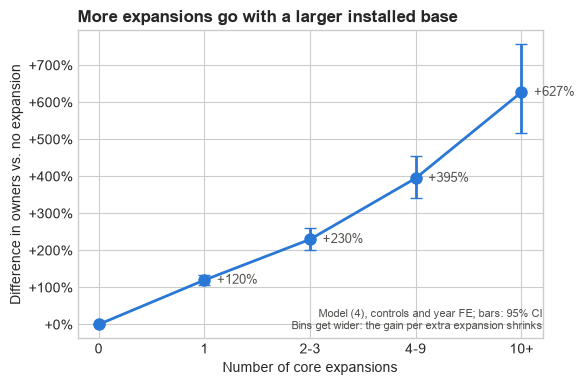

In [44]:
table_expansion_bin_effects = pd.DataFrame([effect(m4, t) for t in bin_terms], index=BIN_LABELS[1:])
table_expansion_bin_effects.index.name = "n_expansions"
table_expansion_bin_effects = table_expansion_bin_effects.round(4)
table_expansion_bin_effects.to_csv(TABLES / "table_expansion_bin_effects.csv")

fig, ax = plt.subplots(figsize=(6, 4))
x = np.arange(len(BIN_LABELS))
est = np.r_[0, table_expansion_bin_effects["pct_effect"]]
low, high = np.r_[0, pct(table_expansion_bin_effects["ci_low"])], np.r_[0, pct(table_expansion_bin_effects["ci_high"])]
ax.errorbar(x, est, yerr=[est - low, high - est], fmt="o-", color=BLUE, markersize=8, capsize=4, linewidth=2)
for xi, e in zip(x[1:], est[1:]):
    ax.text(xi + 0.12, e, f"+{e:.0%}", va="center", color=GREY, fontsize=9)
ax.set_xticks(x, BIN_LABELS)
ax.yaxis.set_major_formatter(PCT)
ax.set_xlabel("Number of core expansions")
ax.set_ylabel("Difference in owners vs. no expansion")
ax.set_title("More expansions go with a larger installed base")
ax.text(1, 0.02, "Model (4), controls and year FE; bars: 95% CI\nBins get wider: the gain per extra expansion shrinks",
        transform=ax.transAxes, ha="right", va="bottom", color=GREY, fontsize=8)
save_fig(fig, "fig_effect_by_expansion_bin")
table_expansion_bin_effects

## H3 – planned expansion streams (Tables 6–7, Figure 5)

Where the business model is built around a stream of add-ons from the start, publishers release
expansions because the model prescribes them, not only because the base game performed well. An
expansion is then a weaker signal of success, so H3 predicts a **negative interaction**
`has_expansion × planned_expansion_genre`.

| Model | Sample | Why |
|---|---|---|
| (5) | all games | test of H3 |
| (5b) | without wargames | is the result driven by wargames alone? |

In [45]:
print(data.groupby("planned_expansion_genre")["has_expansion"].agg(n_games="size", share_with_expansion="mean")
      .rename(index={0: "Other genres", 1: "Planned-expansion genres"}))

m5 = ols("log_owned ~ has_expansion * planned_expansion_genre", data)
m5b = ols("log_owned ~ has_expansion * planned_expansion_genre", data[data["wargame"] == 0])
h3_terms = ["has_expansion", "planned_expansion_genre", "has_expansion:planned_expansion_genre"]
table_h3_models = regression_table([m5, m5b], ["(5) all games", "(5b) without wargames"], h3_terms + CONTROLS, LABELS)
table_h3_models.to_csv(TABLES / "table_h3_models.csv")
table_h3_models

                          n_games  share_with_expansion
planned_expansion_genre                                
Other genres                14088              0.208191
Planned-expansion genres     3689              0.313364


,(5) all games,(5b) without wargames
Has expansion,1.251***,1.244***
,(0.031),(0.031)
Planned-expansion genre,-0.362***,0.070
,(0.029),(0.063)
Has expansion x planned genre,-0.297***,-0.069
,(0.053),(0.099)
log(playing time),0.132***,0.202***
,(0.013),(0.016)
Min. players,-0.134***,-0.147***
,(0.015),(0.016)


In [46]:
table_h3_group_effects = pd.DataFrame({
    "Other genres": effect(m5, "has_expansion"),
    "Planned-expansion genres": effect(m5, "has_expansion + has_expansion:planned_expansion_genre"),
    "Difference (interaction)": effect(m5, "has_expansion:planned_expansion_genre"),
    "Difference without wargames (5b)": effect(m5b, "has_expansion:planned_expansion_genre"),
}).T
table_h3_group_effects["n_with_expansion"] = [data.query("planned_expansion_genre == 0")["has_expansion"].sum(),
                              data.query("planned_expansion_genre == 1")["has_expansion"].sum(), np.nan, np.nan]
table_h3_group_effects = table_h3_group_effects.round(4)
table_h3_group_effects.to_csv(TABLES / "table_h3_group_effects.csv")

other, planned, diff, diff_nw = (table_h3_group_effects.iloc[i] for i in range(4))
print(f"H3: other genres +{other['pct_effect']:.0%} owners, planned-expansion genres +{planned['pct_effect']:.0%}; "
      f"interaction b = {diff['coef']:.3f} (95% CI [{diff['ci_low']:.3f}, {diff['ci_high']:.3f}], {p_text(diff['p_value'])})")
print(f"    without wargames: b = {diff_nw['coef']:.3f} (SE {diff_nw['se']:.3f}, {p_text(diff_nw['p_value'])})")
table_h3_group_effects

H3: other genres +250% owners, planned-expansion genres +160%; interaction b = -0.297 (95% CI [-0.402, -0.192], p < 0.001)
    without wargames: b = -0.069 (SE 0.099, p = 0.484)


,coef,se,ci_low,ci_high,p_value,pct_effect,n_with_expansion
Other genres,1.2513,0.0310,1.1905,1.3122,0.0000,2.4950,2933.0
Planned-expansion genres,0.9545,0.0439,0.8685,1.0405,0.0000,1.5974,1156.0
Difference (interaction),-0.2968,0.0535,-0.4016,-0.1920,0.0000,-0.2568,NaN
Difference without wargames (5b),-0.0694,0.0990,-0.2635,0.1248,0.4838,-0.0670,NaN


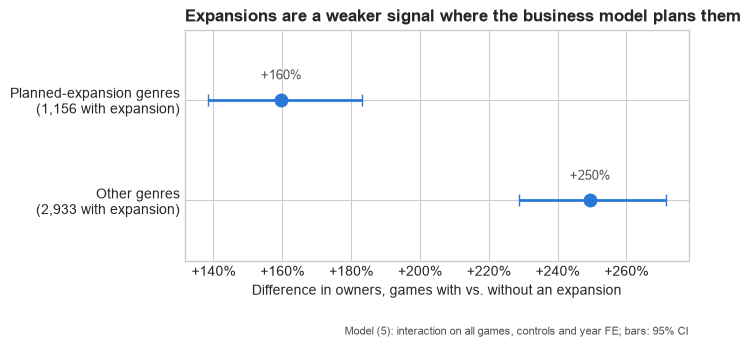

In [47]:
groups = table_h3_group_effects.iloc[:2]
fig, ax = plt.subplots(figsize=(6.5, 3))
y = np.arange(2)
est, low, high = groups["pct_effect"], pct(groups["ci_low"]), pct(groups["ci_high"])
ax.errorbar(est, y, xerr=[est - low, high - est], fmt="o", color=BLUE, markersize=9, capsize=4, linewidth=2)
for yi, e in zip(y, est):
    ax.text(e, yi + 0.18, f"+{e:.0%}", ha="center", va="bottom", color=GREY, fontsize=9)
ax.set_yticks(y, [f"{g}\n({int(n):,} with expansion)" for g, n in zip(groups.index, groups["n_with_expansion"])])
ax.set_ylim(-0.6, 1.7)
ax.xaxis.set_major_formatter(PCT)
ax.set_xlabel("Difference in owners, games with vs. without an expansion")
ax.set_title("Expansions are a weaker signal where the business model plans them")
ax.text(1, -0.32, "Model (5): interaction on all games, controls and year FE; bars: 95% CI",
        transform=ax.transAxes, ha="right", color=GREY, fontsize=8)
save_fig(fig, "fig_h3_business_model")

## Exploratory: expansion gap by category and mechanic (Tables 8–9, Figures 6–7)

Not a hypothesis test; this answers the second part of the research question. For each of the 15 most
common categories and mechanics there is one model on **all games** with the interaction
`has_expansion × group`. The gap shown is the one inside the group (main effect + interaction).
A joint Wald test per family checks whether the gap differs across groups at all.

In [48]:
labels = pd.read_csv(PROCESSED / "dummy_labels.csv")
rows = []
for col, family, label in labels.itertuples(index=False):
    model = ols(f"log_owned ~ has_expansion * {col}", data)
    rows.append({"family": family, "group": label, "n_games": data[col].sum(),
                 "n_with_expansion": data.loc[data[col] == 1, "has_expansion"].sum(),
                 **effect(model, f"has_expansion + has_expansion:{col}"),
                 "interaction_p": model.pvalues[f"has_expansion:{col}"]})
table_exploratory_effects = pd.DataFrame(rows)
table_exploratory_effects.round(4).to_csv(TABLES / "table_exploratory_effects.csv", index=False)

wald = {}
for family, cols in labels.groupby("family")["column"]:
    model = ols(f"log_owned ~ has_expansion * ({' + '.join(cols)})", data)
    test = model.wald_test(", ".join(f"has_expansion:{c} = 0" for c in cols), scalar=True)
    wald[family] = {"df": len(cols), "wald_chi2": float(test.statistic), "p_value": float(test.pvalue)}
table_exploratory_wald_tests = pd.DataFrame(wald).T
table_exploratory_wald_tests = table_exploratory_wald_tests.round(4)

table_exploratory_wald_tests.to_csv(TABLES / "table_exploratory_wald_tests.csv")
table_exploratory_wald_tests

,df,wald_chi2,p_value
categories,15.0,142.2999,0.0
mechanics,15.0,103.4084,0.0


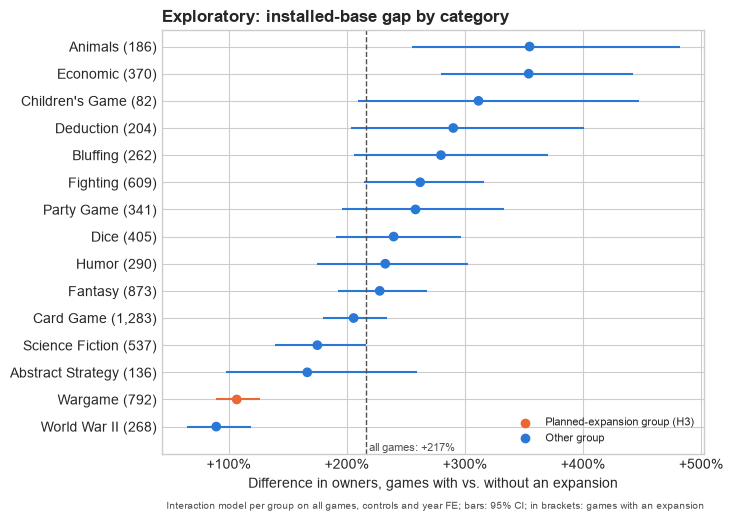

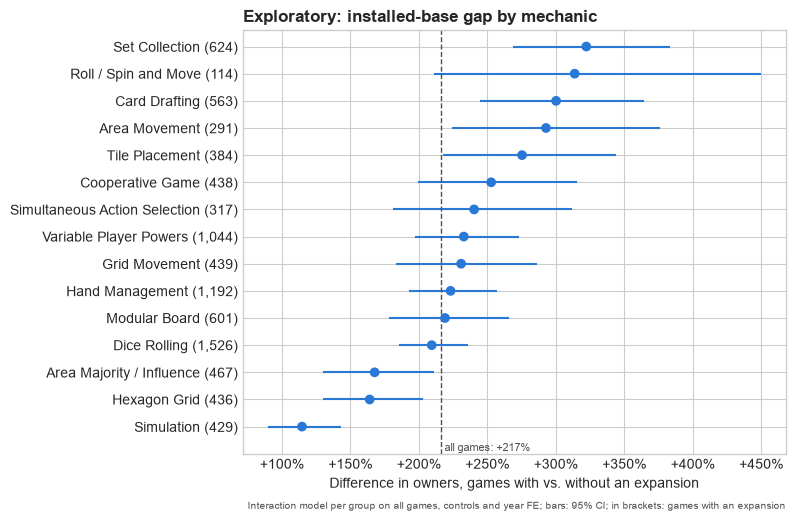

In [49]:
planned_groups = {"Wargame", "Miniatures", "Collectible Components", "Scenario / Mission / Campaign Game"}

def plot_effects(family, title, name):
    table = table_exploratory_effects[table_exploratory_effects["family"] == family].sort_values("coef")
    fig, ax = plt.subplots(figsize=(7, 5.5))
    y = np.arange(len(table))
    est, low, high = table["pct_effect"], pct(table["ci_low"]), pct(table["ci_high"])
    colors = [ORANGE if g in planned_groups else BLUE for g in table["group"]]
    ax.scatter(est, y, color=colors, zorder=3)
    ax.hlines(y, low, high, color=colors, linewidth=1.5)
    ax.axvline(h1["pct_effect"], color=GREY, linestyle="--", linewidth=1)
    ax.text(h1["pct_effect"], -0.9, f" all games: +{h1['pct_effect']:.0%}", color=GREY, fontsize=8)
    ax.set_yticks(y, [f"{g} ({n:,})" for g, n in zip(table["group"], table["n_with_expansion"])])
    ax.set_ylim(-1, len(table) - 0.4)
    ax.xaxis.set_major_formatter(PCT)
    ax.set_xlabel("Difference in owners, games with vs. without an expansion")
    ax.set_title(title)
    if any(g in planned_groups for g in table["group"]):
        ax.scatter([], [], color=ORANGE, label="Planned-expansion group (H3)")
        ax.scatter([], [], color=BLUE, label="Other group")
        ax.legend(loc="lower right", fontsize=8)
    ax.text(1, -0.13, "Interaction model per group on all games, controls and year FE; bars: 95% CI; "
            "in brackets: games with an expansion", transform=ax.transAxes, ha="right", color=GREY, fontsize=7.5)
    save_fig(fig, name)

plot_effects("categories", "Exploratory: installed-base gap by category", "fig_exploratory_category")
plot_effects("mechanics", "Exploratory: installed-base gap by mechanic", "fig_exploratory_mechanic")

## Robustness of H1 (Table 10)

| Check | Assumption it addresses |
|---|---|
| All listed expansions | measurement error: promos and generic packs counted as well |
| Outcome: log(number of ratings) | installed base measured differently |
| Published 1995+ only | only the modern hobby-game era |
| + average rating | omitted game quality |
| Without influential observations | result not driven by a few games (Cook's D > 4/n) |

In [50]:
influential = m1.get_influence().cooks_distance[0] > 4 / len(data)
checks = {
    "Main model (1)": (m1, "has_expansion"),
    "All listed expansions": (ols("log_owned ~ has_expansion_all", data), "has_expansion_all"),
    "Outcome: log(number of ratings)": (ols("log_users_rated ~ has_expansion", data), "has_expansion"),
    "Published 1995+ only": (ols("log_owned ~ has_expansion", data[data["yearpublished"] >= 1995]), "has_expansion"),
    "+ average rating (model 2)": (m2, "has_expansion"),
    "Without influential obs.": (ols("log_owned ~ has_expansion", data[~influential]), "has_expansion"),
}
table_robustness = pd.DataFrame({name: {**effect(m, term), "n": int(m.nobs)} for name, (m, term) in checks.items()}).T
table_robustness = table_robustness.round(4)

table_robustness.to_csv(TABLES / "table_robustness.csv")
table_robustness

,coef,se,ci_low,ci_high,p_value,pct_effect,n
Main model (1),1.1522,0.0261,1.1009,1.2034,0.0,2.1651,17777.0
All listed expansions,1.1713,0.0247,1.1229,1.2197,0.0,2.2260,17777.0
Outcome: log(number of ratings),1.2466,0.0292,1.1893,1.3039,0.0,2.4785,17777.0
Published 1995+ only,1.1557,0.0277,1.1013,1.2100,0.0,2.1762,14796.0
+ average rating (model 2),0.9866,0.0251,0.9374,1.0359,0.0,1.6822,17777.0
Without influential obs.,1.1105,0.0247,1.0621,1.1589,0.0,2.0358,17179.0


## Assumption checks (Table 11, Figure 8)

Breusch-Pagan test for heteroskedasticity (reason for robust standard errors), variance inflation
factors for multicollinearity, share of influential observations, and residual plots of model (1).

In [51]:
bp_stat, bp_p, _, _ = het_breuschpagan(m1.resid, m1.model.exog)
X = sm.add_constant(data[["has_expansion"] + CONTROLS].astype(float))
vif = {f"VIF {LABELS[c]}": variance_inflation_factor(X.values, i) for i, c in enumerate(X.columns) if c != "const"}
table_assumption_tests = pd.Series({
    "Breusch-Pagan LM": bp_stat,
    "Breusch-Pagan p-value": bp_p,
    "Influential obs. (Cook's D > 4/n)": influential.sum(),
    "Share influential": influential.mean(),
    **vif,
}, name="value").to_frame()
table_assumption_tests = table_assumption_tests.round(4)

table_assumption_tests.to_csv(TABLES / "table_assumption_tests.csv")
table_assumption_tests

,value
Breusch-Pagan LM,646.6841
Breusch-Pagan p-value,0.0000
Influential obs. (Cook's D > 4/n),598.0000
Share influential,0.0336
VIF Has expansion,1.0587
VIF log(playing time),1.4509
VIF Min. players,1.1128
VIF Max. players (capped),1.1100
VIF Min. age,1.4518
VIF log(publisher size),1.1658


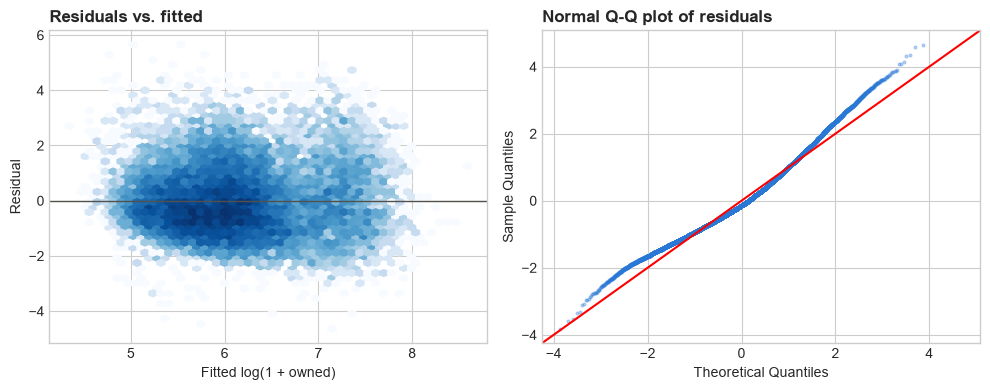

In [52]:
fig, axes = plt.subplots(1, 2, figsize=(10, 4))
axes[0].hexbin(m1.fittedvalues, m1.resid, gridsize=50, cmap="Blues", mincnt=1, bins="log")
axes[0].axhline(0, color=GREY, linewidth=1)
axes[0].set_xlabel("Fitted log(1 + owned)")
axes[0].set_ylabel("Residual")
axes[0].set_title("Residuals vs. fitted")
sm.qqplot(m1.resid / m1.resid.std(), line="45", ax=axes[1], markersize=2, alpha=0.3,
          markerfacecolor=BLUE, markeredgecolor=BLUE)
axes[1].set_title("Normal Q-Q plot of residuals")
fig.tight_layout()
save_fig(fig, "fig_residual_diagnostics")